# 05B — Ablasi penuh Curah Hujan

Konfigurasi tahap kelima tetap kecuali pengeluaran Curah Hujan dan seluruh turunannya.
Imputer/scaler di-fit ulang tanpa hujan. Test akhir tidak dimuat nilainya atau dievaluasi.
Lengan utama: train bersama baru. Sensitivitas: timestamp train bersama lama persis.
Tidak ada preprocessing final dipilih. Implementasi: `scripts/ablation_5b.py`.


In [1]:
from pathlib import Path
import sys,os
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
os.environ.setdefault('MPLCONFIGDIR',str(ROOT/'outputs/.mplconfig'))
from IPython.display import display,Markdown,Image
import pandas as pd
from ablation_5b import Ablation
experiment=Ablation().prepare()
display(pd.DataFrame(experiment.invariants))
print('Kovariat tersisa:',experiment.cov)
print('Konfigurasi dikunci:',experiment.config_hash)

5B dikunci. Curah Hujan tidak ada pada matriks/daftar kovariat; belum ada Ridge dilatih.
Kovariat tersisa: ['PM10', 'PM2.5', 'CO', 'O3', 'NO2', 'Kec.Angin', 'Kelembaban', 'Suhu', 'Tek.Udara', 'Sol.Rad']
Konfigurasi dikunci: a79225e0f1136d8a5158dc5a414871ef1c39c084c7aae50be5b440ed0dc3ba02


,Parameter,Sama dengan tahap 5,Nilai
0,split,True,"[{'Split': 'train', 'Awal': '2025-01-01 00:00:..."
1,horizon_slots,True,1
2,horizon_minutes,True,30
3,so2_lags,True,"[0, 1, 2, 6, 12, 24, 48]"
4,covariate_lag_slots,True,1
5,ffill_limit_slots,True,4
6,knn,True,"{'k': 10, 'weights': 'distance', 'metric': 'na..."
7,ridge,True,"{'alpha': 1.0, 'fit_intercept': True, 'solver'..."
8,warmup_slots,True,4320
9,prefix_update_slots,True,1440


## Gate sebelum melatih Ridge

Imputasi histori memakai prefix train yang sama, tanpa Curah Hujan pada matriks imputer.
Verifikasi jumlah/komposisi train bersama dan pengamatan >2,14 yang kembali masuk.
2,14 adalah alat penelusuran kohort lama, bukan ambang kualitas/bahaya.
Sel berikut wajib lolos sebelum enam Ridge (tiga per lengan) dilatih.


In [2]:
experiment.impute_and_gate()
display(pd.DataFrame(experiment.flow))
display(pd.DataFrame([experiment.gate]))
display(pd.DataFrame(experiment.train_distribution))
display(pd.DataFrame(experiment.monthly_added))
print('Ridge yang telah dilatih:',experiment.ridge_fit_count)

Histori kausal: 2025-04-01 00:00:00 - 2025-04-30 23:30:00
Histori kausal: 2025-05-01 00:00:00 - 2025-05-30 23:30:00
Histori kausal: 2025-05-31 00:00:00 - 2025-06-29 23:30:00
Histori kausal: 2025-06-30 00:00:00 - 2025-07-29 23:30:00
Histori kausal: 2025-07-30 00:00:00 - 2025-08-28 23:30:00
Histori kausal: 2025-08-29 00:00:00 - 2025-09-27 23:30:00
Histori kausal: 2025-09-28 00:00:00 - 2025-10-27 23:30:00
Histori kausal: 2025-10-28 00:00:00 - 2025-11-26 23:30:00
Histori kausal: 2025-11-27 00:00:00 - 2025-12-26 23:30:00
Histori kausal: 2025-12-27 00:00:00 - 2026-01-25 23:30:00
Histori kausal: 2026-01-26 00:00:00 - 2026-02-24 23:30:00
Histori kausal: 2026-02-25 00:00:00 - 2026-03-16 23:00:00
Histori kausal: 2026-03-16 23:30:00 - 2026-06-19 05:30:00
GATE LULUS sebelum Ridge: {'Ridge fit count saat pemeriksaan': 0, 'Train bersama lama': 12654, 'Train bersama baru': 16530, 'Tambahan timestamp': 3876, 'Timestamp lama tidak lagi layak': 0, 'Target tinggi lama': 0, 'Target tinggi baru': 3786, 'Ta

,Pipeline,Tahap,Jumlah sampel,Target asli teramati,Origin awal,Origin akhir,Target awal,Target akhir,Minimum SO2,Median SO2,Maksimum SO2,Mean SO2,SD SO2,Target lebih 2.14
0,P0_median,01 Seluruh slot origin train,21119,19198,2025-01-01 00:00:00,2026-03-16 23:00:00,2025-01-01 00:30:00,2026-03-16 23:30:00,0.92,1.61,80.71,13.974758,20.392987,5289
1,P0_median,02 Target t+1 asli teramati,19198,19198,2025-01-02 11:00:00,2026-03-16 23:00:00,2025-01-02 11:30:00,2026-03-16 23:30:00,0.92,1.61,80.71,13.974758,20.392987,5289
2,P0_median,03 Setelah lag struktural tersedia,19198,19198,2025-01-02 11:00:00,2026-03-16 23:00:00,2025-01-02 11:30:00,2026-03-16 23:30:00,0.92,1.61,80.71,13.974758,20.392987,5289
3,P0_median,04 Setelah kalibrasi 90 hari,16707,16707,2025-04-01 00:00:00,2026-03-16 23:00:00,2025-04-01 00:30:00,2026-03-16 23:30:00,1.04,1.60,47.81,11.766891,18.531564,3889
4,P0_median,05 Setelah buffer lag 48 slot,16659,16659,2025-04-02 00:00:00,2026-03-16 23:00:00,2025-04-02 00:30:00,2026-03-16 23:30:00,1.04,1.60,47.81,11.670000,18.469958,3841
5,P0_median,"06 Setelah imputasi, tanpa membuang sisa NaN",16659,16659,2025-04-02 00:00:00,2026-03-16 23:00:00,2025-04-02 00:30:00,2026-03-16 23:30:00,1.04,1.60,47.81,11.670000,18.469958,3841
6,P0_median,07 Setelah pemeriksaan 34 fitur finite,16659,16659,2025-04-02 00:00:00,2026-03-16 23:00:00,2025-04-02 00:30:00,2026-03-16 23:30:00,1.04,1.60,47.81,11.670000,18.469958,3841
7,P0_median,08 Setelah purge target validasi,16658,16658,2025-04-02 00:00:00,2026-03-16 22:30:00,2025-04-02 00:30:00,2026-03-16 23:00:00,1.04,1.60,47.81,11.670611,18.470344,3841
8,P1_ffill_L4,01 Seluruh slot origin train,21119,19198,2025-01-01 00:00:00,2026-03-16 23:00:00,2025-01-01 00:30:00,2026-03-16 23:30:00,0.92,1.61,80.71,13.974758,20.392987,5289
9,P1_ffill_L4,02 Target t+1 asli teramati,19198,19198,2025-01-02 11:00:00,2026-03-16 23:00:00,2025-01-02 11:30:00,2026-03-16 23:30:00,0.92,1.61,80.71,13.974758,20.392987,5289


,Ridge fit count saat pemeriksaan,Train bersama lama,Train bersama baru,Tambahan timestamp,Timestamp lama tidak lagi layak,Target tinggi lama,Target tinggi baru,Target tinggi kembali masuk,Minimum target baru,Median target baru,Maksimum target baru,Konfigurasi SHA256,Test dimuat,Test dievaluasi
0,0,12654,16530,3876,0,0,3786,3786,1.04,1.6,47.81,a79225e0f1136d8a5158dc5a414871ef1c39c084c7aae5...,False,False


,Lengan,Bulan,Jumlah sampel,Target asli teramati,Origin awal,Origin akhir,Target awal,Target akhir,Minimum SO2,Median SO2,Maksimum SO2,Mean SO2,SD SO2,Target lebih 2.14
0,Tahap5_dengan_hujan,seluruh kohort,12654,12654,2025-06-22 23:30:00,2026-03-16 22:30:00,2025-06-23 00:00:00,2026-03-16 23:00:00,1.04,1.560,2.14,1.561050,0.129673,0
1,Tahap5_dengan_hujan,2025-06,384,384,2025-06-22 23:30:00,2025-06-30 23:00:00,2025-06-23 00:00:00,2025-06-30 23:30:00,1.07,1.560,2.03,1.553672,0.145433,0
2,Tahap5_dengan_hujan,2025-07,1429,1429,2025-06-30 23:30:00,2025-07-31 23:00:00,2025-07-01 00:00:00,2025-07-31 23:30:00,1.07,1.560,2.10,1.558006,0.138265,0
3,Tahap5_dengan_hujan,2025-08,1433,1433,2025-07-31 23:30:00,2025-08-31 23:00:00,2025-08-01 00:00:00,2025-08-31 23:30:00,1.04,1.560,2.05,1.563112,0.108493,0
4,Tahap5_dengan_hujan,2025-09,1436,1436,2025-08-31 23:30:00,2025-09-30 23:00:00,2025-09-01 00:00:00,2025-09-30 23:30:00,1.05,1.560,2.08,1.558015,0.117824,0
5,Tahap5_dengan_hujan,2025-10,1486,1486,2025-09-30 23:30:00,2025-10-31 23:00:00,2025-10-01 00:00:00,2025-10-31 23:30:00,1.04,1.560,2.14,1.559569,0.150659,0
6,Tahap5_dengan_hujan,2025-11,1439,1439,2025-10-31 23:30:00,2025-11-30 23:00:00,2025-11-01 00:00:00,2025-11-30 23:30:00,1.12,1.560,2.07,1.563336,0.133989,0
7,Tahap5_dengan_hujan,2025-12,1484,1484,2025-11-30 23:30:00,2025-12-31 23:00:00,2025-12-01 00:00:00,2025-12-31 23:30:00,1.08,1.570,2.03,1.570148,0.136489,0
8,Tahap5_dengan_hujan,2026-01,1482,1482,2025-12-31 23:30:00,2026-01-31 23:00:00,2026-01-01 00:00:00,2026-01-31 23:30:00,1.12,1.570,2.04,1.567578,0.123213,0
9,Tahap5_dengan_hujan,2026-02,1317,1317,2026-01-31 23:30:00,2026-02-28 23:00:00,2026-02-01 00:00:00,2026-02-28 23:30:00,1.08,1.550,2.02,1.551359,0.120714,0


,Bulan target,Train lama,Train baru,Perubahan jumlah,Target lebih 2.14 lama,Target lebih 2.14 baru
0,2025-04,0,1379,1379,0,1379
1,2025-05,0,1364,1364,0,1364
2,2025-06,384,1440,1056,0,1043
3,2025-07,1429,1455,26,0,0
4,2025-08,1433,1484,51,0,0
5,2025-09,1436,1436,0,0,0
6,2025-10,1486,1486,0,0,0
7,2025-11,1439,1439,0,0,0
8,2025-12,1484,1484,0,0,0
9,2026-01,1482,1482,0,0,0


## Utama dan sensitivitas

Semua konfigurasi Ridge identik dengan tahap kelima; scaler fitur di-fit pada kohort train
masing-masing. Hasil lama hanya dibaca. Perbandingan memakai irisan timestamp identik
untuk hasil lama dan dua lengan baru. Persistence memakai donor asli dan umur yang sama.


,Lengan,Pipeline,Domain,Jumlah prediksi,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif,SHA256 timestamp target
0,5B_train_lama_tetap,P0_median,seluruh berhasil,4524,4524,100.000000,0.081652,0.105549,0.000408,0,3c8dd6f13653ffed6e21279cf6eb9ff7c66e80ea686b43...
1,5B_train_lama_tetap,P0_median,irisan internal 5B,4487,4524,99.182140,0.081443,0.105307,0.000207,0,07c6593b5604cd00ff23346493a4f90174685a0b0c76bf...
2,5B_train_lama_tetap,P1_ffill_L4,seluruh berhasil,4489,4524,99.226348,0.081455,0.105285,0.000125,0,c0a88f4c3743008ff8e323e6fa58de43d906306238e476...
3,5B_train_lama_tetap,P1_ffill_L4,irisan internal 5B,4487,4524,99.182140,0.081454,0.105289,0.000146,0,07c6593b5604cd00ff23346493a4f90174685a0b0c76bf...
4,5B_train_lama_tetap,P2_knn_k10,seluruh berhasil,4522,4524,99.955791,0.081661,0.105537,0.000362,0,9182feb0b3e7b9169c83572aa0ffd7af50d3683097630c...
5,5B_train_lama_tetap,P2_knn_k10,irisan internal 5B,4487,4524,99.182140,0.081451,0.105286,0.000148,0,07c6593b5604cd00ff23346493a4f90174685a0b0c76bf...
6,5B_train_lama_tetap,Persistence,seluruh berhasil,4524,4524,100.000000,0.115975,0.148921,0.000029,0,3c8dd6f13653ffed6e21279cf6eb9ff7c66e80ea686b43...
7,5B_train_lama_tetap,Persistence,irisan internal 5B,4487,4524,99.182140,0.115830,0.148758,-0.000172,0,07c6593b5604cd00ff23346493a4f90174685a0b0c76bf...
8,5B_train_diperluas,P0_median,seluruh berhasil,4524,4524,100.000000,0.102080,0.167196,0.004115,2,3c8dd6f13653ffed6e21279cf6eb9ff7c66e80ea686b43...
9,5B_train_diperluas,P0_median,irisan internal 5B,4487,4524,99.182140,0.101889,0.167191,0.004040,2,07c6593b5604cd00ff23346493a4f90174685a0b0c76bf...


,Lengan,Pipeline,Domain,Jumlah prediksi,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif,SHA256 timestamp target
0,Tahap5_dengan_hujan,P0_median,irisan identik lama dan kedua 5B,4487,4524,99.18214,0.081446,0.105314,0.000343,0,07c6593b5604cd00ff23346493a4f90174685a0b0c76bf...
1,Tahap5_dengan_hujan,P1_ffill_L4,irisan identik lama dan kedua 5B,4487,4524,99.18214,0.081452,0.105289,0.000230,0,07c6593b5604cd00ff23346493a4f90174685a0b0c76bf...
2,Tahap5_dengan_hujan,P2_knn_k10,irisan identik lama dan kedua 5B,4487,4524,99.18214,0.081457,0.105296,0.000287,0,07c6593b5604cd00ff23346493a4f90174685a0b0c76bf...
3,Tahap5_dengan_hujan,Persistence,irisan identik lama dan kedua 5B,4487,4524,99.18214,0.115830,0.148758,-0.000172,0,07c6593b5604cd00ff23346493a4f90174685a0b0c76bf...
4,5B_train_lama_tetap,P0_median,irisan identik lama dan kedua 5B,4487,4524,99.18214,0.081443,0.105307,0.000207,0,07c6593b5604cd00ff23346493a4f90174685a0b0c76bf...
5,5B_train_lama_tetap,P1_ffill_L4,irisan identik lama dan kedua 5B,4487,4524,99.18214,0.081454,0.105289,0.000146,0,07c6593b5604cd00ff23346493a4f90174685a0b0c76bf...
6,5B_train_lama_tetap,P2_knn_k10,irisan identik lama dan kedua 5B,4487,4524,99.18214,0.081451,0.105286,0.000148,0,07c6593b5604cd00ff23346493a4f90174685a0b0c76bf...
7,5B_train_lama_tetap,Persistence,irisan identik lama dan kedua 5B,4487,4524,99.18214,0.115830,0.148758,-0.000172,0,07c6593b5604cd00ff23346493a4f90174685a0b0c76bf...
8,5B_train_diperluas,P0_median,irisan identik lama dan kedua 5B,4487,4524,99.18214,0.101889,0.167191,0.004040,2,07c6593b5604cd00ff23346493a4f90174685a0b0c76bf...
9,5B_train_diperluas,P1_ffill_L4,irisan identik lama dan kedua 5B,4487,4524,99.18214,0.099935,0.128656,0.000733,0,07c6593b5604cd00ff23346493a4f90174685a0b0c76bf...


,Bulan target,Lengan,Pipeline,Domain,Jumlah prediksi,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif,SHA256 timestamp target
0,2026-03,Tahap5_dengan_hujan,P0_median,irisan identik lama dan kedua 5B,715,721,99.167822,0.074956,0.094128,0.000593,0,3de4863ef836e68072d88965ec77628727024f7b31e6db...
1,2026-04,Tahap5_dengan_hujan,P0_median,irisan identik lama dan kedua 5B,1417,1438,98.539638,0.079504,0.102632,-0.000256,0,88781b19f4ffa479d44f294c57138a9515145a0f20fc67...
2,2026-05,Tahap5_dengan_hujan,P0_median,irisan identik lama dan kedua 5B,1484,1488,99.731183,0.085911,0.113431,0.000127,0,cd660e86bfa76012d91acf092c0af717e0c9ace0e86418...
3,2026-06,Tahap5_dengan_hujan,P0_median,irisan identik lama dan kedua 5B,871,877,99.315849,0.082326,0.103946,0.001478,0,02dffc768d3eba01e645a1737e9eb9791be5cced3a73c2...
4,2026-03,Tahap5_dengan_hujan,P1_ffill_L4,irisan identik lama dan kedua 5B,715,721,99.167822,0.074997,0.094151,0.000487,0,3de4863ef836e68072d88965ec77628727024f7b31e6db...
5,2026-04,Tahap5_dengan_hujan,P1_ffill_L4,irisan identik lama dan kedua 5B,1417,1438,98.539638,0.079468,0.102496,-0.000375,0,88781b19f4ffa479d44f294c57138a9515145a0f20fc67...
6,2026-05,Tahap5_dengan_hujan,P1_ffill_L4,irisan identik lama dan kedua 5B,1484,1488,99.731183,0.085928,0.113402,0.000013,0,cd660e86bfa76012d91acf092c0af717e0c9ace0e86418...
7,2026-06,Tahap5_dengan_hujan,P1_ffill_L4,irisan identik lama dan kedua 5B,871,877,99.315849,0.082353,0.104070,0.001372,0,02dffc768d3eba01e645a1737e9eb9791be5cced3a73c2...
8,2026-03,Tahap5_dengan_hujan,P2_knn_k10,irisan identik lama dan kedua 5B,715,721,99.167822,0.074998,0.094140,0.000501,0,3de4863ef836e68072d88965ec77628727024f7b31e6db...
9,2026-04,Tahap5_dengan_hujan,P2_knn_k10,irisan identik lama dan kedua 5B,1417,1438,98.539638,0.079477,0.102509,-0.000324,0,88781b19f4ffa479d44f294c57138a9515145a0f20fc67...


,Perbandingan,Pipeline,Sebelum,Sesudah,Jumlah target identik,Delta MAE,Delta RMSE,Delta bias,Catatan
0,Ablasi pada train tetap,P0_median,Tahap5_dengan_hujan,5B_train_lama_tetap,4487,-0.000003,-6.992546e-06,-0.000136,Delta=sesudah−sebelum; bukan klaim pengaruh mu...
1,Ablasi pada train tetap,P1_ffill_L4,Tahap5_dengan_hujan,5B_train_lama_tetap,4487,0.000002,-2.365636e-07,-0.000083,Delta=sesudah−sebelum; bukan klaim pengaruh mu...
2,Ablasi pada train tetap,P2_knn_k10,Tahap5_dengan_hujan,5B_train_lama_tetap,4487,-0.000007,-9.645580e-06,-0.000140,Delta=sesudah−sebelum; bukan klaim pengaruh mu...
3,Penambahan train tanpa hujan,P0_median,5B_train_lama_tetap,5B_train_diperluas,4487,0.020446,6.188454e-02,0.003833,Delta=sesudah−sebelum; bukan klaim pengaruh mu...
4,Penambahan train tanpa hujan,P1_ffill_L4,5B_train_lama_tetap,5B_train_diperluas,4487,0.018481,2.336706e-02,0.000587,Delta=sesudah−sebelum; bukan klaim pengaruh mu...
5,Penambahan train tanpa hujan,P2_knn_k10,5B_train_lama_tetap,5B_train_diperluas,4487,0.018454,2.334886e-02,0.000571,Delta=sesudah−sebelum; bukan klaim pengaruh mu...
6,Gabungan ablasi dan train baru,P0_median,Tahap5_dengan_hujan,5B_train_diperluas,4487,0.020443,6.187754e-02,0.003697,Delta=sesudah−sebelum; bukan klaim pengaruh mu...
7,Gabungan ablasi dan train baru,P1_ffill_L4,Tahap5_dengan_hujan,5B_train_diperluas,4487,0.018483,2.336682e-02,0.000504,Delta=sesudah−sebelum; bukan klaim pengaruh mu...
8,Gabungan ablasi dan train baru,P2_knn_k10,Tahap5_dengan_hujan,5B_train_diperluas,4487,0.018447,2.333921e-02,0.000431,Delta=sesudah−sebelum; bukan klaim pengaruh mu...


,Lengan,Pipeline,Jumlah train,Scaler fitur fit detik,Ridge fit detik,Predict detik
0,5B_train_diperluas,P0_median,16530,0.031063,0.058951,0.003161
1,5B_train_diperluas,P1_ffill_L4,16530,0.024910,0.042601,0.001924
2,5B_train_diperluas,P2_knn_k10,16530,0.018053,0.027047,0.002287
3,5B_train_lama_tetap,P0_median,12654,0.014455,0.029654,0.003869
4,5B_train_lama_tetap,P1_ffill_L4,12654,0.017097,0.040401,0.004391
5,5B_train_lama_tetap,P2_knn_k10,12654,0.021892,0.036771,0.004059


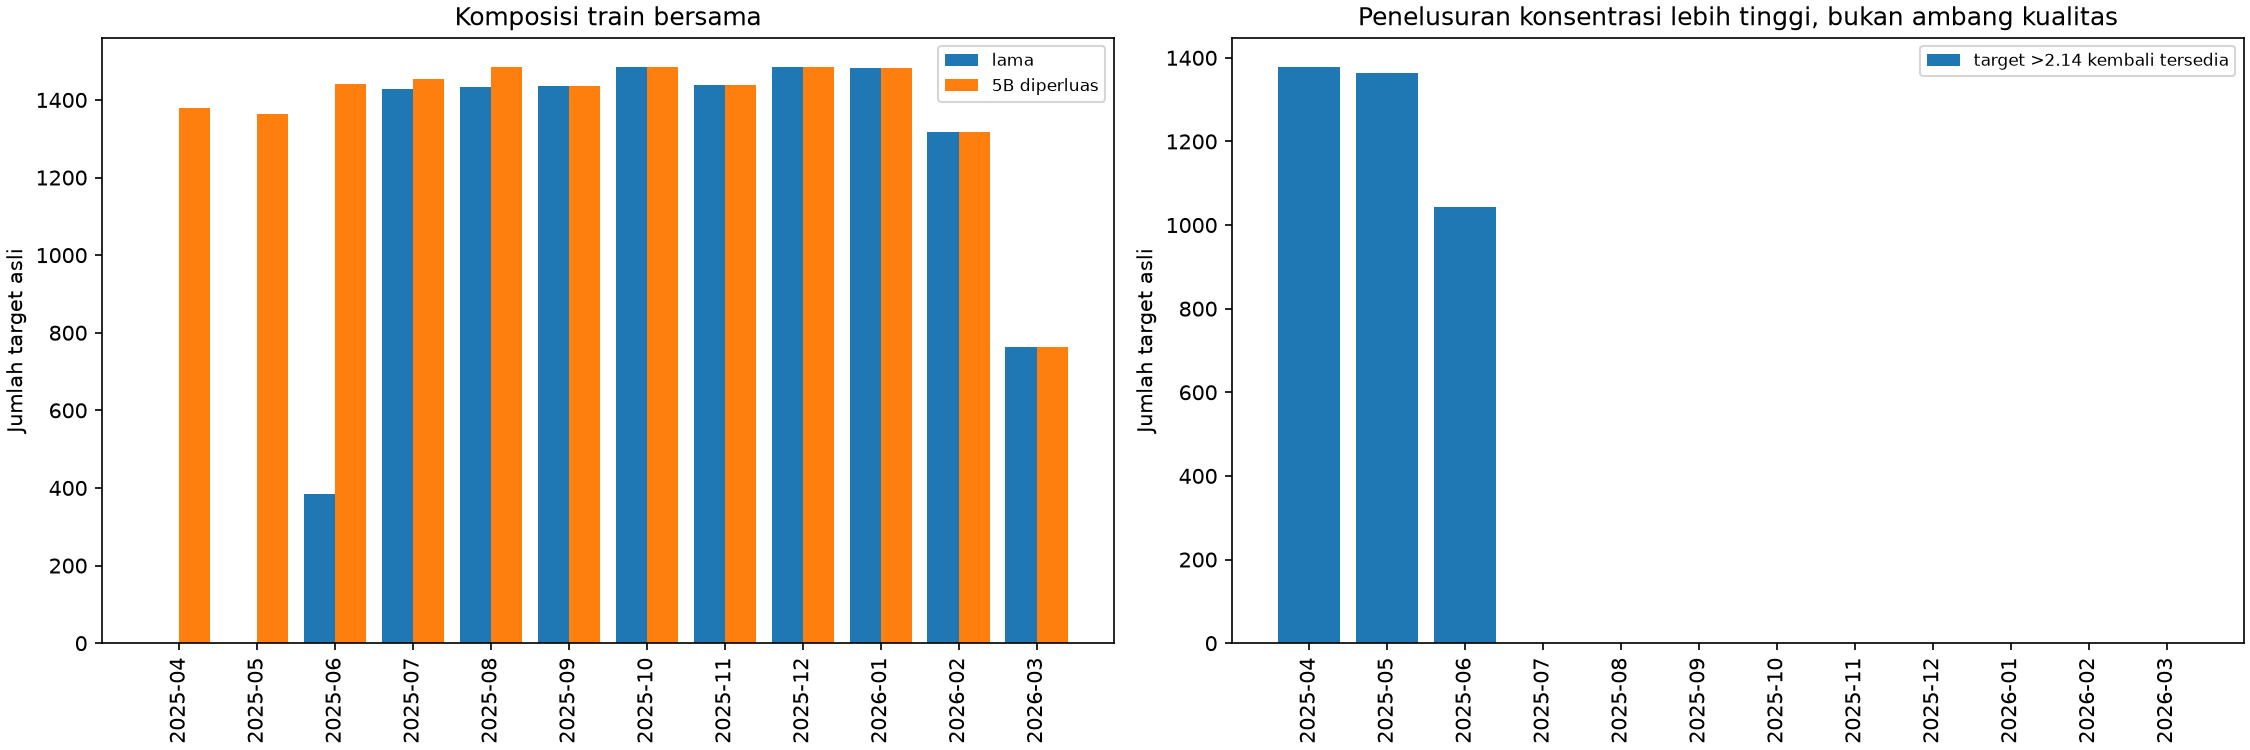

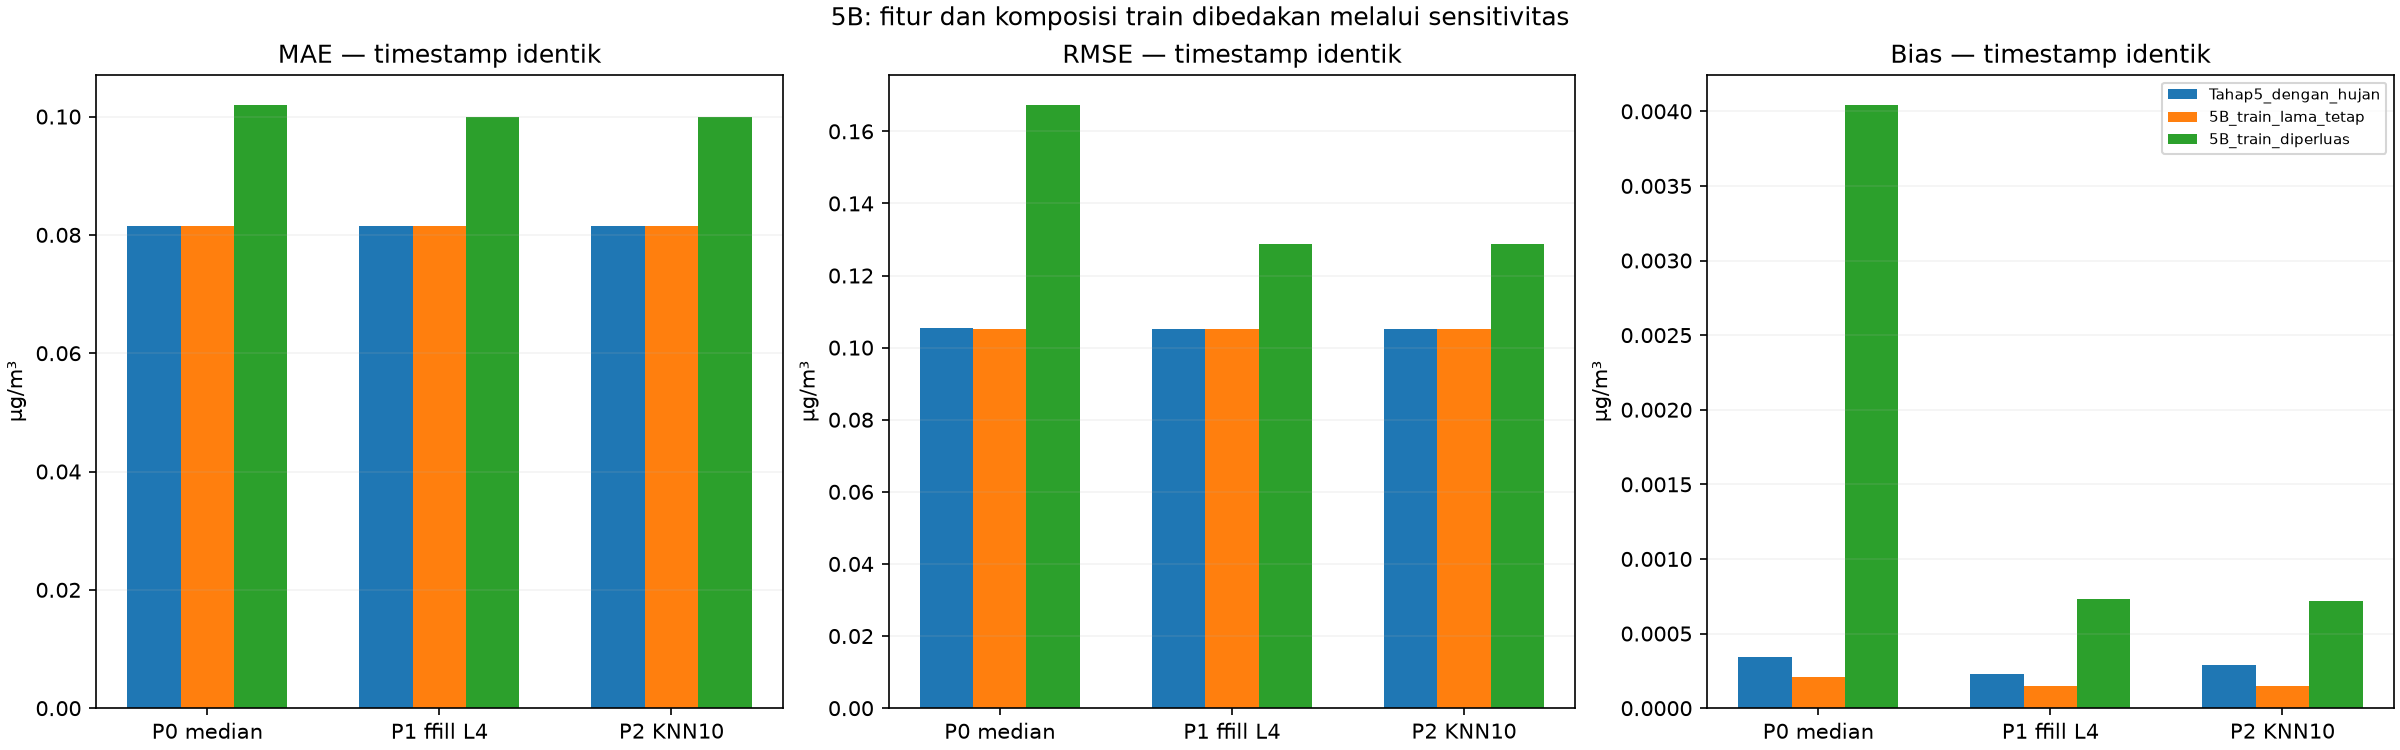

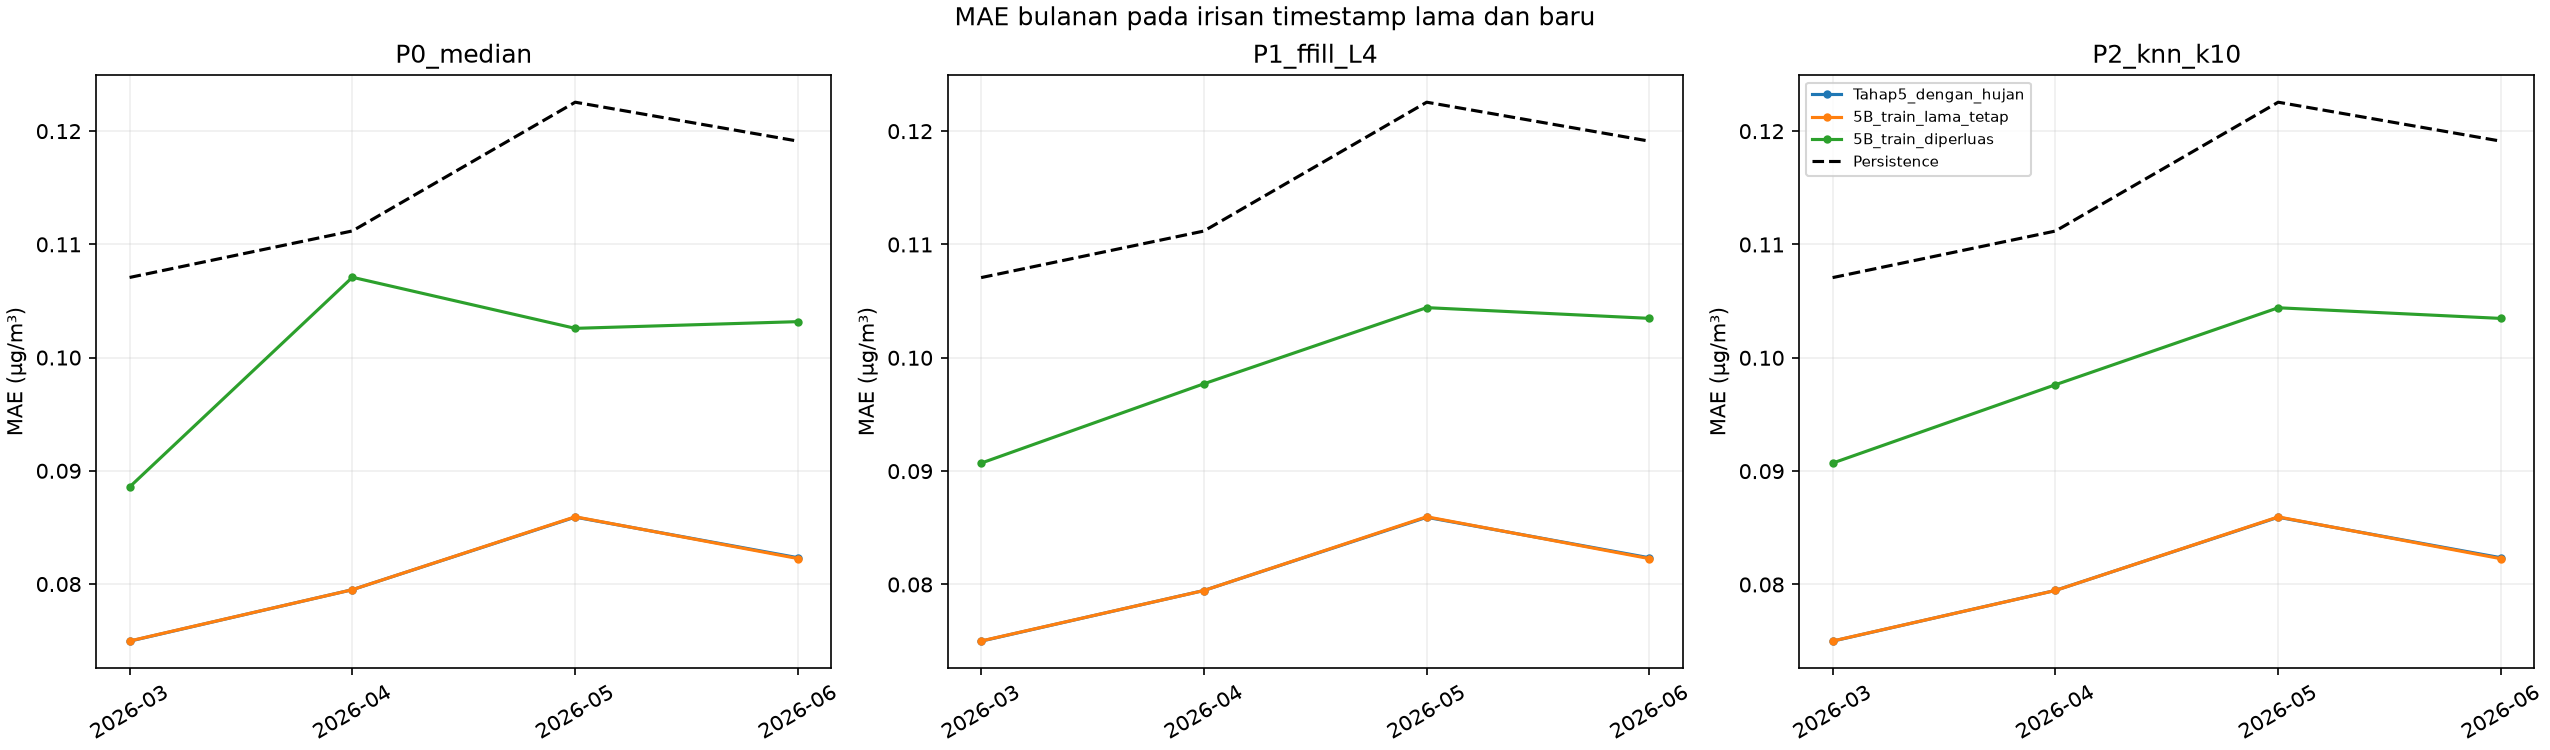

,File,SHA256 sebelum,SHA256 sesudah,Identik
0,outputs\audit_kualitas_data.xlsx,7e1a6059f5660aa50deec62ae7d498361fadafa0b4e093...,7e1a6059f5660aa50deec62ae7d498361fadafa0b4e093...,True
1,outputs\audit_kualitas_tables.json,89bf7a39781e9ea3368a8c7a4731cf7c8c36523eb117a2...,89bf7a39781e9ea3368a8c7a4731cf7c8c36523eb117a2...,True
2,outputs\audit_struktur_data.json,75de5795076e22bb46784e70b238b2778a7e77f75953e9...,75de5795076e22bb46784e70b238b2778a7e77f75953e9...,True
3,outputs\environment_freeze.txt,9137e9aad6f786fe6db4e0ef7fa7b8bbb6f2a400d17de6...,9137e9aad6f786fe6db4e0ef7fa7b8bbb6f2a400d17de6...,True
4,outputs\forecasting_acuan_way_urang.xlsx,1bfd0761f299d27faf7455448520ac11d8231feb7fc8d5...,1bfd0761f299d27faf7455448520ac11d8231feb7fc8d5...,True
...,...,...,...,...
69,notebooks\01_audit_data.ipynb,5870504f9d16d342161cd82ba14b554e21aee5604df47b...,5870504f9d16d342161cd82ba14b554e21aee5604df47b...,True
70,notebooks\02_audit_kualitas_data.ipynb,031948f8d28d754b8fe0bf6a04e4341d01a7af32ff1054...,031948f8d28d754b8fe0bf6a04e4341d01a7af32ff1054...,True
71,notebooks\04_pilot_imputasi_way_urang.ipynb,5d505fd390bf47153b587fde96c2b7016fde07cc51593a...,5d505fd390bf47153b587fde96c2b7016fde07cc51593a...,True
72,notebooks\05_forecasting_acuan_way_urang.ipynb,630eab31b3eada0aa7cb01bf889aba89062c3dfbb14c83...,630eab31b3eada0aa7cb01bf889aba89062c3dfbb14c83...,True


In [3]:
experiment.run_models()
display(pd.DataFrame(experiment.metrics))
display(pd.DataFrame(experiment.compare))
display(pd.DataFrame(experiment.compare_month))
display(pd.DataFrame(experiment.deltas))
display(pd.DataFrame(experiment.timing))
for name in ['perluasan_train.png','perbandingan_identik.png','bulanan_identik.png']:
    display(Image(filename=str(ROOT/'outputs/figures/ablasi_curah_hujan_5B'/name)))
display(pd.DataFrame(experiment.integrity))

## Ekspor dan kesimpulan

Efek utama menggabungkan ablasi dan perubahan komposisi train. Sensitivitas train lama
menguji ablasi pada sampel tetap; perbandingan dua lengan tanpa hujan menilai penambahan
sampel. Validasi tetap berkonsentrasi rendah, sehingga kemampuan pada konsentrasi tinggi
tidak dapat disimpulkan hanya karena pengamatan tinggi kembali masuk train.


In [4]:
experiment.export_excel()
report=(ROOT/'outputs/ringkasan_5B_ablasi_curah_hujan.md').read_text(encoding='utf-8')
display(Markdown(report.replace('(figures/', '(../outputs/figures/')))
print('Selesai. Sumber dan hasil lama identik; test tidak dimuat/dievaluasi.')

{"kind":"table","sheet":"Ringkasan","address":"A1:F4","rows":4,"cols":6,"values":[["Lengan","Pipeline","Domain","Jumlah prediksi","Denominator target asli","Cakupan persen"],["Tahap5_dengan_hujan","P0_median","irisan identik lama dan kedua 5B",4487,4524,99.18213969938108],["Tahap5_dengan_hujan","P1_ffill_L4","irisan identik lama dan kedua 5B",4487,4524,99.18213969938108],["Tahap5_dengan_hujan","P2_knn_k10","irisan identik lama dan kedua 5B",4487,4524,99.18213969938108]]}
Inspect result written to file: C:\Users\INTAN\airpollutan_SO2\outputs\hasil_5B_ablasi_curah_hujan.xlsx.inspect.ndjson
Ekspor selesai: 18 sheet.

Selesai. Sumber dan hasil lama identik; test tidak dimuat/dievaluasi.


# Tahap 5B — ablasi Curah Hujan pada pilot Way Urang

**Eksperimen terpisah; seluruh sumber dan artefak lama dipertahankan.** Test akhir tidak dimuat nilainya atau dievaluasi. Hanya Ridge dengan konfigurasi tahap kelima digunakan. P3 tetap ditunda. Ini bukan pemilihan preprocessing final.

## 1. Rancangan dan perubahan yang diizinkan

- Curah Hujan dikeluarkan dari **matriks imputasi**, scaler jarak KNN, fitur Ridge, dan indikator missing terkait. Sepuluh kovariat tersisa sama untuk ketiga pipeline. Imputer/scaler prefix diestimasi ulang, bukan sekadar menghapus kolom dari hasil imputasi lama.
- P0 median, P1 forward fill L4 tanpa fallback, P2 KNN k10 berbobot distance/nan_euclidean. Guard minimum dua kovariat asli tetap **dua**, meskipun jumlah kovariat berkurang. Tidak ada parameter yang dilonggarkan.
- Split70/15/15, horizon30menit, lagSO₂0/1/2/6/12/24/48, lagkovariat1, kalibrasi90hari, buffer48slot, pembaruanprefix30hari, aturan kualitas dan `Ridge(alpha=1, fit_intercept=True, solver=svd)` tetap seperti tahap5.
- Histori train dibentuk dari prefix yang berakhir sebelum query. Saat validasi, imputer/scaler jarak dibekukan dari seluruh train, histori lama tidak dihitung ulang. Tidak ada target masa depan menjadi fitur, donor atau nilai pengisi. Tidak ada clipping/fallback tambahan.
- Fitur Ridge menjadi **34 kolom**: tujuh lag SO₂, sepuluh kovariat lag1 dan tujuh belas indikator missing asli. Nol, lonjakan, pola konstan dan ledger off-grid dipertahankan sesuai aturan lama.
- Asumsi latensi tidak berubah: SO₂(u) dianggap tersedia saat origin u; kovariat(u−1) dianggap sudah tiba pada u. Waktu kedatangan aktual masih perlu konfirmasi penyedia data.
- Dua lengan memakai **histori tanpa hujan yang sama**: `5B_train_diperluas` memakai train bersama baru; `5B_train_lama_tetap` memakai timestamp Ridge train lama persis. Imputer prefix memakai bagian train yang diizinkan, bukan validasi, pada kedua lengan.
- Konfigurasi disimpan sebelum fit di `ablasi_curah_hujan_5B/config_locked.json`, SHA256 `a79225e0f1136d8a5158dc5a414871ef1c39c084c7aae50be5b440ed0dc3ba02`. Gate kelayakan disimpan ketika hitungan Ridge fit masih nol.

| Parameter | Sama dengan tahap 5 | Nilai |
|---|---|---|
| split | True | [{'Split': 'train', 'Awal': '2025-01-01 00:00:00', 'Akhir': '2026-03-16 23:00:00', 'Jumlah slot': 21119, 'Jumlah baris sumber': 20915, 'SO2 nonkosong asli': 19197, 'Status': 'Digunakan sesuai kontrak'}, {'Split': 'validation', 'Awal': '2026-03-16 23:30:00', 'Akhir': '2026-06-19 06:00:00', 'Jumlah slot': 4526, 'Jumlah baris sumber': 4525, 'SO2 nonkosong asli': 4524, 'Status': 'Digunakan sesuai kontrak'}, {'Split': 'test', 'Awal': '2026-06-19 06:30:00', 'Akhir': '2026-09-21 13:00:00', 'Jumlah slot': 4526, 'Jumlah baris sumber': 4525, 'SO2 nonkosong asli': 4525, 'Status': 'Hanya inventaris, tidak dievaluasi'}] |
| horizon_slots | True | 1 |
| horizon_minutes | True | 30 |
| so2_lags | True | [0, 1, 2, 6, 12, 24, 48] |
| covariate_lag_slots | True | 1 |
| ffill_limit_slots | True | 4 |
| knn | True | {'k': 10, 'weights': 'distance', 'metric': 'nan_euclidean', 'minimum_original_covariates': 2} |
| ridge | True | {'alpha': 1.0, 'fit_intercept': True, 'solver': 'svd'} |
| warmup_slots | True | 4320 |
| prefix_update_slots | True | 1440 |
| train_input_history | True | expanding prefix, fit cutoff eksklusif awal blok |
| validation_imputer | True | frozen seluruh train; histori masa lalu tidak dihitung ulang |
| availability | True | SO2(u) diasumsikan tersedia pada origin u; kovariat(u-1) diasumsikan tersedia pada u. Latensi aktual belum diketahui. |
| quality | True | nol, lonjakan, konstan dan ekstrem dipertahankan; ledger off-grid tahap 4 tidak dipetakan |
| threads | True | 1 |
| seed | True | 42 |
| pipelines | True | ['P0_median', 'P1_ffill_L4', 'P2_knn_k10'] |
| P3 | True | ditunda karena belum konvergen dan hasil negatif pada pilot |

## 2. Verifikasi sampel sebelum pelatihan Ridge

Gate **lulus sebelum Ridge**: train bersama bertambah dari **12654** menjadi **16530**; tambahan **3876** origin. Seluruh timestamp train lama tetap layak (0 hilang). Pengamatan target **>2,14 µg/m³** bertambah dari **0** menjadi **3786**, seluruh tambahannya kembali masuk. Rentang target baru **1.04–47.81 µg/m³**, median **1.6**.

**2,14 hanya ambang penelusuran kohort lama**, bukan batas kualitas, bahaya atau outlier. Nilai tidak dihapus berdasarkan konsentrasi. Gate ini dilakukan setelah rekonstruksi histori agar kelengkapan fitur dapat diketahui, tetapi sebelum ada model Ridge dilatih.

### Alur per pipeline

Seperti penelusuran sebelumnya, tahap awal memakai origin pada train dengan target t+1. Satu target awal validasi muncul sebelum purge. Inventaris train murni tetap 19.197 SO₂ teramati; pasangan origin mempunyai19.198 target teramati sebelum purge. Lag struktural hanya memeriksa indeks waktu, bukan membuang missing sebelum imputasi.

| Pipeline | Tahap | Jumlah sampel | Target asli teramati | Minimum SO2 | Median SO2 | Maksimum SO2 | Target lebih 2.14 |
|---|---|---|---|---|---|---|---|
| P0_median | 01 Seluruh slot origin train | 21119 | 19198 | 0.92 | 1.61 | 80.71 | 5289 |
| P0_median | 02 Target t+1 asli teramati | 19198 | 19198 | 0.92 | 1.61 | 80.71 | 5289 |
| P0_median | 03 Setelah lag struktural tersedia | 19198 | 19198 | 0.92 | 1.61 | 80.71 | 5289 |
| P0_median | 04 Setelah kalibrasi 90 hari | 16707 | 16707 | 1.04 | 1.60 | 47.81 | 3889 |
| P0_median | 05 Setelah buffer lag 48 slot | 16659 | 16659 | 1.04 | 1.60 | 47.81 | 3841 |
| P0_median | 06 Setelah imputasi, tanpa membuang sisa NaN | 16659 | 16659 | 1.04 | 1.60 | 47.81 | 3841 |
| P0_median | 07 Setelah pemeriksaan 34 fitur finite | 16659 | 16659 | 1.04 | 1.60 | 47.81 | 3841 |
| P0_median | 08 Setelah purge target validasi | 16658 | 16658 | 1.04 | 1.60 | 47.81 | 3841 |
| P1_ffill_L4 | 01 Seluruh slot origin train | 21119 | 19198 | 0.92 | 1.61 | 80.71 | 5289 |
| P1_ffill_L4 | 02 Target t+1 asli teramati | 19198 | 19198 | 0.92 | 1.61 | 80.71 | 5289 |
| P1_ffill_L4 | 03 Setelah lag struktural tersedia | 19198 | 19198 | 0.92 | 1.61 | 80.71 | 5289 |
| P1_ffill_L4 | 04 Setelah kalibrasi 90 hari | 16707 | 16707 | 1.04 | 1.60 | 47.81 | 3889 |
| P1_ffill_L4 | 05 Setelah buffer lag 48 slot | 16659 | 16659 | 1.04 | 1.60 | 47.81 | 3841 |
| P1_ffill_L4 | 06 Setelah imputasi, tanpa membuang sisa NaN | 16659 | 16659 | 1.04 | 1.60 | 47.81 | 3841 |
| P1_ffill_L4 | 07 Setelah pemeriksaan 34 fitur finite | 16559 | 16559 | 1.04 | 1.60 | 47.81 | 3792 |
| P1_ffill_L4 | 08 Setelah purge target validasi | 16558 | 16558 | 1.04 | 1.60 | 47.81 | 3792 |
| P2_knn_k10 | 01 Seluruh slot origin train | 21119 | 19198 | 0.92 | 1.61 | 80.71 | 5289 |
| P2_knn_k10 | 02 Target t+1 asli teramati | 19198 | 19198 | 0.92 | 1.61 | 80.71 | 5289 |
| P2_knn_k10 | 03 Setelah lag struktural tersedia | 19198 | 19198 | 0.92 | 1.61 | 80.71 | 5289 |
| P2_knn_k10 | 04 Setelah kalibrasi 90 hari | 16707 | 16707 | 1.04 | 1.60 | 47.81 | 3889 |
| P2_knn_k10 | 05 Setelah buffer lag 48 slot | 16659 | 16659 | 1.04 | 1.60 | 47.81 | 3841 |
| P2_knn_k10 | 06 Setelah imputasi, tanpa membuang sisa NaN | 16659 | 16659 | 1.04 | 1.60 | 47.81 | 3841 |
| P2_knn_k10 | 07 Setelah pemeriksaan 34 fitur finite | 16582 | 16582 | 1.04 | 1.60 | 47.81 | 3786 |
| P2_knn_k10 | 08 Setelah purge target validasi | 16581 | 16581 | 1.04 | 1.60 | 47.81 | 3786 |
| P0_median | 09 Final bersama baru, gate sebelum Ridge | 16530 | 16530 | 1.04 | 1.60 | 47.81 | 3786 |
| P1_ffill_L4 | 09 Final bersama baru, gate sebelum Ridge | 16530 | 16530 | 1.04 | 1.60 | 47.81 | 3786 |
| P2_knn_k10 | 09 Final bersama baru, gate sebelum Ridge | 16530 | 16530 | 1.04 | 1.60 | 47.81 | 3786 |

### Distribusi dan perubahan train per bulan

| Lengan | Bulan | Jumlah sampel | Target awal | Target akhir | Minimum SO2 | Median SO2 | Maksimum SO2 | Target lebih 2.14 |
|---|---|---|---|---|---|---|---|---|
| Tahap5_dengan_hujan | seluruh kohort | 12654 | 2025-06-23 00:00:00 | 2026-03-16 23:00:00 | 1.04 | 1.56 | 2.14 | 0 |
| Tahap5_dengan_hujan | 2025-06 | 384 | 2025-06-23 00:00:00 | 2025-06-30 23:30:00 | 1.07 | 1.56 | 2.03 | 0 |
| Tahap5_dengan_hujan | 2025-07 | 1429 | 2025-07-01 00:00:00 | 2025-07-31 23:30:00 | 1.07 | 1.56 | 2.10 | 0 |
| Tahap5_dengan_hujan | 2025-08 | 1433 | 2025-08-01 00:00:00 | 2025-08-31 23:30:00 | 1.04 | 1.56 | 2.05 | 0 |
| Tahap5_dengan_hujan | 2025-09 | 1436 | 2025-09-01 00:00:00 | 2025-09-30 23:30:00 | 1.05 | 1.56 | 2.08 | 0 |
| Tahap5_dengan_hujan | 2025-10 | 1486 | 2025-10-01 00:00:00 | 2025-10-31 23:30:00 | 1.04 | 1.56 | 2.14 | 0 |
| Tahap5_dengan_hujan | 2025-11 | 1439 | 2025-11-01 00:00:00 | 2025-11-30 23:30:00 | 1.12 | 1.56 | 2.07 | 0 |
| Tahap5_dengan_hujan | 2025-12 | 1484 | 2025-12-01 00:00:00 | 2025-12-31 23:30:00 | 1.08 | 1.57 | 2.03 | 0 |
| Tahap5_dengan_hujan | 2026-01 | 1482 | 2026-01-01 00:00:00 | 2026-01-31 23:30:00 | 1.12 | 1.57 | 2.04 | 0 |
| Tahap5_dengan_hujan | 2026-02 | 1317 | 2026-02-01 00:00:00 | 2026-02-28 23:30:00 | 1.08 | 1.55 | 2.02 | 0 |
| Tahap5_dengan_hujan | 2026-03 | 764 | 2026-03-01 00:00:00 | 2026-03-16 23:00:00 | 1.16 | 1.56 | 1.97 | 0 |
| 5B_train_lama_tetap | seluruh kohort | 12654 | 2025-06-23 00:00:00 | 2026-03-16 23:00:00 | 1.04 | 1.56 | 2.14 | 0 |
| 5B_train_lama_tetap | 2025-06 | 384 | 2025-06-23 00:00:00 | 2025-06-30 23:30:00 | 1.07 | 1.56 | 2.03 | 0 |
| 5B_train_lama_tetap | 2025-07 | 1429 | 2025-07-01 00:00:00 | 2025-07-31 23:30:00 | 1.07 | 1.56 | 2.10 | 0 |
| 5B_train_lama_tetap | 2025-08 | 1433 | 2025-08-01 00:00:00 | 2025-08-31 23:30:00 | 1.04 | 1.56 | 2.05 | 0 |
| 5B_train_lama_tetap | 2025-09 | 1436 | 2025-09-01 00:00:00 | 2025-09-30 23:30:00 | 1.05 | 1.56 | 2.08 | 0 |
| 5B_train_lama_tetap | 2025-10 | 1486 | 2025-10-01 00:00:00 | 2025-10-31 23:30:00 | 1.04 | 1.56 | 2.14 | 0 |
| 5B_train_lama_tetap | 2025-11 | 1439 | 2025-11-01 00:00:00 | 2025-11-30 23:30:00 | 1.12 | 1.56 | 2.07 | 0 |
| 5B_train_lama_tetap | 2025-12 | 1484 | 2025-12-01 00:00:00 | 2025-12-31 23:30:00 | 1.08 | 1.57 | 2.03 | 0 |
| 5B_train_lama_tetap | 2026-01 | 1482 | 2026-01-01 00:00:00 | 2026-01-31 23:30:00 | 1.12 | 1.57 | 2.04 | 0 |
| 5B_train_lama_tetap | 2026-02 | 1317 | 2026-02-01 00:00:00 | 2026-02-28 23:30:00 | 1.08 | 1.55 | 2.02 | 0 |
| 5B_train_lama_tetap | 2026-03 | 764 | 2026-03-01 00:00:00 | 2026-03-16 23:00:00 | 1.16 | 1.56 | 1.97 | 0 |
| 5B_train_diperluas | seluruh kohort | 16530 | 2025-04-02 00:30:00 | 2026-03-16 23:00:00 | 1.04 | 1.60 | 47.81 | 3786 |
| 5B_train_diperluas | 2025-04 | 1379 | 2025-04-02 00:30:00 | 2025-04-30 23:30:00 | 43.53 | 45.40 | 47.43 | 1379 |
| 5B_train_diperluas | 2025-05 | 1364 | 2025-05-01 00:00:00 | 2025-05-31 23:30:00 | 43.75 | 45.39 | 47.81 | 1364 |
| 5B_train_diperluas | 2025-06 | 1440 | 2025-06-01 00:00:00 | 2025-06-30 23:30:00 | 1.07 | 45.09 | 47.78 | 1043 |
| 5B_train_diperluas | 2025-07 | 1455 | 2025-07-01 00:00:00 | 2025-07-31 23:30:00 | 1.07 | 1.56 | 2.10 | 0 |
| 5B_train_diperluas | 2025-08 | 1484 | 2025-08-01 00:00:00 | 2025-08-31 23:30:00 | 1.04 | 1.56 | 2.05 | 0 |
| 5B_train_diperluas | 2025-09 | 1436 | 2025-09-01 00:00:00 | 2025-09-30 23:30:00 | 1.05 | 1.56 | 2.08 | 0 |
| 5B_train_diperluas | 2025-10 | 1486 | 2025-10-01 00:00:00 | 2025-10-31 23:30:00 | 1.04 | 1.56 | 2.14 | 0 |
| 5B_train_diperluas | 2025-11 | 1439 | 2025-11-01 00:00:00 | 2025-11-30 23:30:00 | 1.12 | 1.56 | 2.07 | 0 |
| 5B_train_diperluas | 2025-12 | 1484 | 2025-12-01 00:00:00 | 2025-12-31 23:30:00 | 1.08 | 1.57 | 2.03 | 0 |
| 5B_train_diperluas | 2026-01 | 1482 | 2026-01-01 00:00:00 | 2026-01-31 23:30:00 | 1.12 | 1.57 | 2.04 | 0 |
| 5B_train_diperluas | 2026-02 | 1317 | 2026-02-01 00:00:00 | 2026-02-28 23:30:00 | 1.08 | 1.55 | 2.02 | 0 |
| 5B_train_diperluas | 2026-03 | 764 | 2026-03-01 00:00:00 | 2026-03-16 23:00:00 | 1.16 | 1.56 | 1.97 | 0 |

| Bulan target | Train lama | Train baru | Perubahan jumlah | Target lebih 2.14 lama | Target lebih 2.14 baru |
|---|---|---|---|---|---|
| 2025-04 | 0 | 1379 | 1379 | 0 | 1379 |
| 2025-05 | 0 | 1364 | 1364 | 0 | 1364 |
| 2025-06 | 384 | 1440 | 1056 | 0 | 1043 |
| 2025-07 | 1429 | 1455 | 26 | 0 | 0 |
| 2025-08 | 1433 | 1484 | 51 | 0 | 0 |
| 2025-09 | 1436 | 1436 | 0 | 0 | 0 |
| 2025-10 | 1486 | 1486 | 0 | 0 | 0 |
| 2025-11 | 1439 | 1439 | 0 | 0 | 0 |
| 2025-12 | 1484 | 1484 | 0 | 0 | 0 |
| 2026-01 | 1482 | 1482 | 0 | 0 | 0 |
| 2026-02 | 1317 | 1317 | 0 | 0 | 0 |
| 2026-03 | 764 | 764 | 0 | 0 | 0 |

![Perluasan train](../outputs/figures/ablasi_curah_hujan_5B/perluasan_train.png)

## 3. Hasil utama dan cakupan

Target evaluasi selalu SO₂ asli teramati. `e=prediksi−pengamatan`, MAE=mean(abs(e)), RMSE=sqrt(mean(e²)), bias=mean(e), satuanµg/m³. Cakupan(%)=prediksi finite/seluruh target asli validasi×100%. Pada tabel bulanan denominator hanya target asli bulan itu. Prediksi negatif, bila ada, dilaporkan tanpa clipping.
Persistence tidak dilatih. Donornya SO₂ asli terakhir pada/sebelum origin dengan umur yang sama persis seperti tahap kelima; kesamaan nilai dan usia donor diverifikasi.

| Lengan | Pipeline | Domain | Jumlah prediksi | Denominator target asli | Cakupan persen | MAE | RMSE | Bias | Prediksi negatif |
|---|---|---|---|---|---|---|---|---|---|
| 5B_train_lama_tetap | P0_median | seluruh berhasil | 4524 | 4524 | 100.000 | 0.081652 | 0.105549 | 0.000408 | 0 |
| 5B_train_lama_tetap | P0_median | irisan internal 5B | 4487 | 4524 | 99.182 | 0.081443 | 0.105307 | 0.000207 | 0 |
| 5B_train_lama_tetap | P1_ffill_L4 | seluruh berhasil | 4489 | 4524 | 99.226 | 0.081455 | 0.105285 | 0.000125 | 0 |
| 5B_train_lama_tetap | P1_ffill_L4 | irisan internal 5B | 4487 | 4524 | 99.182 | 0.081454 | 0.105289 | 0.000146 | 0 |
| 5B_train_lama_tetap | P2_knn_k10 | seluruh berhasil | 4522 | 4524 | 99.956 | 0.081661 | 0.105537 | 0.000362 | 0 |
| 5B_train_lama_tetap | P2_knn_k10 | irisan internal 5B | 4487 | 4524 | 99.182 | 0.081451 | 0.105286 | 0.000148 | 0 |
| 5B_train_lama_tetap | Persistence | seluruh berhasil | 4524 | 4524 | 100.000 | 0.115975 | 0.148921 | 0.000029 | 0 |
| 5B_train_lama_tetap | Persistence | irisan internal 5B | 4487 | 4524 | 99.182 | 0.115830 | 0.148758 | -0.000172 | 0 |
| 5B_train_diperluas | P0_median | seluruh berhasil | 4524 | 4524 | 100.000 | 0.102080 | 0.167196 | 0.004115 | 2 |
| 5B_train_diperluas | P0_median | irisan internal 5B | 4487 | 4524 | 99.182 | 0.101889 | 0.167191 | 0.004040 | 2 |
| 5B_train_diperluas | P1_ffill_L4 | seluruh berhasil | 4489 | 4524 | 99.226 | 0.099959 | 0.128675 | 0.000802 | 0 |
| 5B_train_diperluas | P1_ffill_L4 | irisan internal 5B | 4487 | 4524 | 99.182 | 0.099935 | 0.128656 | 0.000733 | 0 |
| 5B_train_diperluas | P2_knn_k10 | seluruh berhasil | 4522 | 4524 | 99.956 | 0.100081 | 0.128909 | 0.000805 | 0 |
| 5B_train_diperluas | P2_knn_k10 | irisan internal 5B | 4487 | 4524 | 99.182 | 0.099905 | 0.128635 | 0.000719 | 0 |
| 5B_train_diperluas | Persistence | seluruh berhasil | 4524 | 4524 | 100.000 | 0.115975 | 0.148921 | 0.000029 | 0 |
| 5B_train_diperluas | Persistence | irisan internal 5B | 4487 | 4524 | 99.182 | 0.115830 | 0.148758 | -0.000172 | 0 |

Tabel `Bulanan_5B_cakupan` pada workbook memuat domain seluruh berhasil dan irisan internal5B setiap bulan untuk kedua lengan. Skor domain masing-masing tidak digunakan sebagai pengganti perbandingan timestamp identik.

## 4. Perbandingan lama dan baru pada target identik

Irisan global mencakup **4487/4524 target asli validasi (99.182%)**: ketiga pipeline dan persistence harus finite pada kondisi lama, 5B trainlama dan 5B traindiperluas. Semua baris perbandingan memakai hash timestamp target yang sama. Ini menjaga perubahan eligibility evaluasi tidak tercampur dengan perubahan skor.

| Lengan | Pipeline | Jumlah prediksi | Cakupan persen | MAE | RMSE | Bias | Prediksi negatif |
|---|---|---|---|---|---|---|---|
| Tahap5_dengan_hujan | P0_median | 4487 | 99.182 | 0.081446 | 0.105314 | 0.000343 | 0 |
| Tahap5_dengan_hujan | P1_ffill_L4 | 4487 | 99.182 | 0.081452 | 0.105289 | 0.000230 | 0 |
| Tahap5_dengan_hujan | P2_knn_k10 | 4487 | 99.182 | 0.081457 | 0.105296 | 0.000287 | 0 |
| Tahap5_dengan_hujan | Persistence | 4487 | 99.182 | 0.115830 | 0.148758 | -0.000172 | 0 |
| 5B_train_lama_tetap | P0_median | 4487 | 99.182 | 0.081443 | 0.105307 | 0.000207 | 0 |
| 5B_train_lama_tetap | P1_ffill_L4 | 4487 | 99.182 | 0.081454 | 0.105289 | 0.000146 | 0 |
| 5B_train_lama_tetap | P2_knn_k10 | 4487 | 99.182 | 0.081451 | 0.105286 | 0.000148 | 0 |
| 5B_train_lama_tetap | Persistence | 4487 | 99.182 | 0.115830 | 0.148758 | -0.000172 | 0 |
| 5B_train_diperluas | P0_median | 4487 | 99.182 | 0.101889 | 0.167191 | 0.004040 | 2 |
| 5B_train_diperluas | P1_ffill_L4 | 4487 | 99.182 | 0.099935 | 0.128656 | 0.000733 | 0 |
| 5B_train_diperluas | P2_knn_k10 | 4487 | 99.182 | 0.099905 | 0.128635 | 0.000719 | 0 |
| 5B_train_diperluas | Persistence | 4487 | 99.182 | 0.115830 | 0.148758 | -0.000172 | 0 |

![Perbandingan identik](../outputs/figures/ablasi_curah_hujan_5B/perbandingan_identik.png)

### Per bulan pada timestamp identik

| Lengan | Pipeline | Bulan target | Jumlah prediksi | Denominator target asli | Cakupan persen | MAE | RMSE | Bias |
|---|---|---|---|---|---|---|---|---|
| Tahap5_dengan_hujan | P0_median | 2026-03 | 715 | 721 | 99.168 | 0.074956 | 0.094128 | 0.000593 |
| Tahap5_dengan_hujan | P0_median | 2026-04 | 1417 | 1438 | 98.540 | 0.079504 | 0.102632 | -0.000256 |
| Tahap5_dengan_hujan | P0_median | 2026-05 | 1484 | 1488 | 99.731 | 0.085911 | 0.113431 | 0.000127 |
| Tahap5_dengan_hujan | P0_median | 2026-06 | 871 | 877 | 99.316 | 0.082326 | 0.103946 | 0.001478 |
| Tahap5_dengan_hujan | P1_ffill_L4 | 2026-03 | 715 | 721 | 99.168 | 0.074997 | 0.094151 | 0.000487 |
| Tahap5_dengan_hujan | P1_ffill_L4 | 2026-04 | 1417 | 1438 | 98.540 | 0.079468 | 0.102496 | -0.000375 |
| Tahap5_dengan_hujan | P1_ffill_L4 | 2026-05 | 1484 | 1488 | 99.731 | 0.085928 | 0.113402 | 0.000013 |
| Tahap5_dengan_hujan | P1_ffill_L4 | 2026-06 | 871 | 877 | 99.316 | 0.082353 | 0.104070 | 0.001372 |
| Tahap5_dengan_hujan | P2_knn_k10 | 2026-03 | 715 | 721 | 99.168 | 0.074998 | 0.094140 | 0.000501 |
| Tahap5_dengan_hujan | P2_knn_k10 | 2026-04 | 1417 | 1438 | 98.540 | 0.079477 | 0.102509 | -0.000324 |
| Tahap5_dengan_hujan | P2_knn_k10 | 2026-05 | 1484 | 1488 | 99.731 | 0.085932 | 0.113416 | 0.000031 |
| Tahap5_dengan_hujan | P2_knn_k10 | 2026-06 | 871 | 877 | 99.316 | 0.082358 | 0.104068 | 0.001543 |
| Tahap5_dengan_hujan | Persistence | 2026-03 | 715 | 721 | 99.168 | 0.107077 | 0.134025 | -0.000420 |
| Tahap5_dengan_hujan | Persistence | 2026-04 | 1417 | 1438 | 98.540 | 0.111186 | 0.143258 | -0.000247 |
| Tahap5_dengan_hujan | Persistence | 2026-05 | 1484 | 1488 | 99.731 | 0.122554 | 0.159373 | -0.000371 |
| Tahap5_dengan_hujan | Persistence | 2026-06 | 871 | 877 | 99.316 | 0.119116 | 0.150296 | 0.000494 |
| 5B_train_lama_tetap | P0_median | 2026-03 | 715 | 721 | 99.168 | 0.074970 | 0.094159 | 0.000554 |
| 5B_train_lama_tetap | P0_median | 2026-04 | 1417 | 1438 | 98.540 | 0.079503 | 0.102648 | -0.000334 |
| 5B_train_lama_tetap | P0_median | 2026-05 | 1484 | 1488 | 99.731 | 0.085940 | 0.113415 | 0.000065 |
| 5B_train_lama_tetap | P0_median | 2026-06 | 871 | 877 | 99.316 | 0.082252 | 0.103889 | 0.001044 |
| 5B_train_lama_tetap | P1_ffill_L4 | 2026-03 | 715 | 721 | 99.168 | 0.075012 | 0.094177 | 0.000476 |
| 5B_train_lama_tetap | P1_ffill_L4 | 2026-04 | 1417 | 1438 | 98.540 | 0.079466 | 0.102515 | -0.000409 |
| 5B_train_lama_tetap | P1_ffill_L4 | 2026-05 | 1484 | 1488 | 99.731 | 0.085974 | 0.113408 | -0.000004 |
| 5B_train_lama_tetap | P1_ffill_L4 | 2026-06 | 871 | 877 | 99.316 | 0.082278 | 0.104009 | 0.001036 |
| 5B_train_lama_tetap | P2_knn_k10 | 2026-03 | 715 | 721 | 99.168 | 0.075010 | 0.094175 | 0.000465 |
| 5B_train_lama_tetap | P2_knn_k10 | 2026-04 | 1417 | 1438 | 98.540 | 0.079470 | 0.102523 | -0.000400 |
| 5B_train_lama_tetap | P2_knn_k10 | 2026-05 | 1484 | 1488 | 99.731 | 0.085963 | 0.113395 | -0.000030 |
| 5B_train_lama_tetap | P2_knn_k10 | 2026-06 | 871 | 877 | 99.316 | 0.082274 | 0.104006 | 0.001080 |
| 5B_train_lama_tetap | Persistence | 2026-03 | 715 | 721 | 99.168 | 0.107077 | 0.134025 | -0.000420 |
| 5B_train_lama_tetap | Persistence | 2026-04 | 1417 | 1438 | 98.540 | 0.111186 | 0.143258 | -0.000247 |
| 5B_train_lama_tetap | Persistence | 2026-05 | 1484 | 1488 | 99.731 | 0.122554 | 0.159373 | -0.000371 |
| 5B_train_lama_tetap | Persistence | 2026-06 | 871 | 877 | 99.316 | 0.119116 | 0.150296 | 0.000494 |
| 5B_train_diperluas | P0_median | 2026-03 | 715 | 721 | 99.168 | 0.088572 | 0.113322 | 0.005834 |
| 5B_train_diperluas | P0_median | 2026-04 | 1417 | 1438 | 98.540 | 0.107093 | 0.229407 | -0.004726 |
| 5B_train_diperluas | P0_median | 2026-05 | 1484 | 1488 | 99.731 | 0.102583 | 0.134771 | 0.015236 |
| 5B_train_diperluas | P0_median | 2026-06 | 871 | 877 | 99.316 | 0.103174 | 0.129981 | -0.002250 |
| 5B_train_diperluas | P1_ffill_L4 | 2026-03 | 715 | 721 | 99.168 | 0.090706 | 0.114371 | -0.000498 |
| 5B_train_diperluas | P1_ffill_L4 | 2026-04 | 1417 | 1438 | 98.540 | 0.097708 | 0.125983 | 0.000076 |
| 5B_train_diperluas | P1_ffill_L4 | 2026-05 | 1484 | 1488 | 99.731 | 0.104427 | 0.136768 | 0.004400 |
| 5B_train_diperluas | P1_ffill_L4 | 2026-06 | 871 | 877 | 99.316 | 0.103481 | 0.129773 | -0.003433 |
| 5B_train_diperluas | P2_knn_k10 | 2026-03 | 715 | 721 | 99.168 | 0.090709 | 0.114378 | -0.000518 |
| 5B_train_diperluas | P2_knn_k10 | 2026-04 | 1417 | 1438 | 98.540 | 0.097624 | 0.125919 | 0.000102 |
| 5B_train_diperluas | P2_knn_k10 | 2026-05 | 1484 | 1488 | 99.731 | 0.104416 | 0.136765 | 0.004349 |
| 5B_train_diperluas | P2_knn_k10 | 2026-06 | 871 | 877 | 99.316 | 0.103476 | 0.129768 | -0.003449 |
| 5B_train_diperluas | Persistence | 2026-03 | 715 | 721 | 99.168 | 0.107077 | 0.134025 | -0.000420 |
| 5B_train_diperluas | Persistence | 2026-04 | 1417 | 1438 | 98.540 | 0.111186 | 0.143258 | -0.000247 |
| 5B_train_diperluas | Persistence | 2026-05 | 1484 | 1488 | 99.731 | 0.122554 | 0.159373 | -0.000371 |
| 5B_train_diperluas | Persistence | 2026-06 | 871 | 877 | 99.316 | 0.119116 | 0.150296 | 0.000494 |

Maret dan Juni adalah bulan parsial. Perbedaan bulanan harus dibaca bersama jumlah target dan bias, bukan hanya MAE agregat.

![Perbandingan bulanan](../outputs/figures/ablasi_curah_hujan_5B/bulanan_identik.png)

## 5. Analisis sensitivitas

- **Lama→5B trainlama:** timestamp Ridge train tetap. Ini menguji ablasi Curah Hujan pada sampel yang sama, termasuk perubahan representasi akibat refit imputer tanpa hujan. Untuk KNN, jarak dan rekonstruksi kovariat dapat berubah. Bukan sekadar menghapus satu koefisien Ridge.
- **5B trainlama→5B diperluas:** kedua lengan memakai matriks fitur dan histori tanpa hujan yang sama; perubahan berasal dari sampel fit Ridge dan scaler fiturnya yang bertambah. Tidak ada tuning parameter tambahan.
- **Lama→5B diperluas:** gabungan ablasi dan komposisi train baru. Eksperimen utama ini tidak mengisolasi pengaruh murni Curah Hujan. Sensitivitas membantu pemisahan operasional, bukan bukti kausal universal.
- Delta di bawah adalah **sesudah−sebelum** pada timestamp identik. Delta negatif MAE/RMSE berarti lebih rendah. Delta bias bertanda tidak otomatis berarti lebih baik; nilai absolut bias juga perlu dibaca.

| Perbandingan | Pipeline | Jumlah target identik | Delta MAE | Delta RMSE | Delta bias |
|---|---|---|---|---|---|
| Ablasi pada train tetap | P0_median | 4487 | -0.00000299 | -0.00000699 | -0.00013581 |
| Ablasi pada train tetap | P1_ffill_L4 | 4487 | 0.00000221 | -0.00000024 | -0.00008340 |
| Ablasi pada train tetap | P2_knn_k10 | 4487 | -0.00000652 | -0.00000965 | -0.00013991 |
| Penambahan train tanpa hujan | P0_median | 4487 | 0.02044611 | 0.06188454 | 0.00383259 |
| Penambahan train tanpa hujan | P1_ffill_L4 | 4487 | 0.01848068 | 0.02336706 | 0.00058700 |
| Penambahan train tanpa hujan | P2_knn_k10 | 4487 | 0.01845382 | 0.02334886 | 0.00057107 |
| Gabungan ablasi dan train baru | P0_median | 4487 | 0.02044311 | 0.06187754 | 0.00369678 |
| Gabungan ablasi dan train baru | P1_ffill_L4 | 4487 | 0.01848289 | 0.02336682 | 0.00050359 |
| Gabungan ablasi dan train baru | P2_knn_k10 | 4487 | 0.01844730 | 0.02333921 | 0.00043116 |

## 6. Waktu komputasi

Histori/imputer tanpa hujan dibentuk sekali dalam **5.819241 detik**, kemudian dipakai bersama oleh dua lengan. Jangan menggandakan biaya ini saat menjumlah waktu. Prefix log mencatat biaya estimasi median, scaler dan KNN serta transform tiap blok; waktunya terikat mesin dan run ini.

| Lengan | Pipeline | Jumlah train | Scaler fitur fit detik | Ridge fit detik | Predict detik |
|---|---|---|---|---|---|
| 5B_train_diperluas | P0_median | 16530 | 0.031063 | 0.058951 | 0.003161 |
| 5B_train_diperluas | P1_ffill_L4 | 16530 | 0.024910 | 0.042601 | 0.001924 |
| 5B_train_diperluas | P2_knn_k10 | 16530 | 0.018053 | 0.027047 | 0.002287 |
| 5B_train_lama_tetap | P0_median | 12654 | 0.014455 | 0.029654 | 0.003869 |
| 5B_train_lama_tetap | P1_ffill_L4 | 12654 | 0.017097 | 0.040401 | 0.004391 |
| 5B_train_lama_tetap | P2_knn_k10 | 12654 | 0.021892 | 0.036771 | 0.004059 |

Tidak ada refit model lama. Nilai lama disalin dari prediksi tersimpan dan diberi skor ulang hanya pada subset validasi identik.

## 7. Kesimpulan terbatas

1. **Kesetaraan preprocessing:** rentang MAE ketiga pipeline pada timestamp identik adalah 1.11909e-05 pada tahap5, 1.13592e-05 setelah ablasi dengan train tetap, dan 0.00198463 pada train diperluas. Baca selisih ini bersama RMSE, bias, cakupan dan bulan. Kedekatan skor bukan uji formal ekuivalensi.
- Pada train lama tetap, tiga metode tetap sangat dekat setelah Curah Hujan dikeluarkan. Pada train diperluas, kesetaraan deskriptif itu **tidak sepenuhnya bertahan**: RMSE P0 0.167191 dibanding P1 0.128656 dan P2 0.128635. P1 dan P2 masih dekat; perbedaan MAE juga perlu dibaca bersama RMSE/bias dan cakupan.
2. **P0_median:** MAE lama/trainlama tanpa hujan/traindiperluas = 0.081446/0.081443/0.101889; RMSE = 0.105314/0.105307/0.167191. Penambahan train mengubah MAE sebesar +0.020446 pada validasi berkonsentrasi rendah, bukan pada target tinggi.
2. **P1_ffill_L4:** MAE lama/trainlama tanpa hujan/traindiperluas = 0.081452/0.081454/0.099935; RMSE = 0.105289/0.105289/0.128656. Penambahan train mengubah MAE sebesar +0.018481 pada validasi berkonsentrasi rendah, bukan pada target tinggi.
2. **P2_knn_k10:** MAE lama/trainlama tanpa hujan/traindiperluas = 0.081457/0.081451/0.099905; RMSE = 0.105296/0.105286/0.128635. Penambahan train mengubah MAE sebesar +0.018454 pada validasi berkonsentrasi rendah, bukan pada target tinggi.
3. **Periode tinggi dalam train:** pengamatan tinggi kembali menjadi contoh pelatihan, tetapi target validasi masih1,09–2,06µg/m³. Hasil ini menilai generalisasi dari komposisi train baru ke validasi rendah, bukan kemampuan memprediksi konsentrasi tinggi. Pada run ini MAE dan RMSE seluruh pipeline meningkat ketika train tanpa hujan diperluas, sedangkan perubahan pada train tetap sangat kecil. Jadi perubahan besar terutama terjadi pada perbandingan komposisi train di dalam rancangan ini, bukan bukti bahwa Curah Hujan sendiri menjadi penyebab murni. Perluasan cakupan train tidak menjamin skor validasi rendah membaik.
4. **Kandidat pengeluaran Curah Hujan:** layak dipertahankan sebagai kandidat karena mengurangi hambatan kelengkapan dan memperluas cakupan periode train. Kelayakan kualitas ini terpisah dari apakah skor rendah di validasi membaik. Sensitivitas train tetap dan hasil perluasan harus dibaca bersama; jangan menyimpulkan manfaat universal atau memilih preprocessing final.
5. **Batas interpretasi:** satu split, Ridge tunggal alpha tetap, rentang validasi sempit, latensi yang diasumsikan dan validitas sensor yang belum terkonfirmasi membatasi kesimpulan. P3 tetap ditunda. Test akhir tetap dikunci dan tidak digunakan untuk memilih fitur/parameter.

## 8. Artefak, reproduksibilitas dan integritas

- Notebook: `notebooks/05B_ablasi_curah_hujan.ipynb`.
- Workbook: `hasil_5B_ablasi_curah_hujan.xlsx`.
- Folder `ablasi_curah_hujan_5B/`: konfigurasi terkunci, gate sebelum Ridge, daftar train dua lengan, timestamp evaluasi, prediksi kedua lengan, histori kausal dan fitur/indikator tanpa hujan.
- Seluruh artefak lama yang dibaca/hash tidak diubah. File sumber juga diverifikasi SHA256 sebelum/sesudah. Log/cache inspect internal tidak diperlakukan sebagai hasil eksperimen.

- `outputs\audit_kualitas_data.xlsx`: SHA256 sebelum=sesudah=`7e1a6059f5660aa50deec62ae7d498361fadafa0b4e093bccdc7980bc8b2ec97`.
- `outputs\audit_kualitas_tables.json`: SHA256 sebelum=sesudah=`89bf7a39781e9ea3368a8c7a4731cf7c8c36523eb117a2e034113c056e5e0b05`.
- `outputs\audit_struktur_data.json`: SHA256 sebelum=sesudah=`75de5795076e22bb46784e70b238b2778a7e77f75953e96c50140e6cb489d4f5`.
- `outputs\environment_freeze.txt`: SHA256 sebelum=sesudah=`9137e9aad6f786fe6db4e0ef7fa7b8bbb6f2a400d17de6131792bac31ce67e9d`.
- `outputs\forecasting_acuan_way_urang.xlsx`: SHA256 sebelum=sesudah=`1bfd0761f299d27faf7455448520ac11d8231feb7fc8d5ca930ef579a21a3a2c`.
- `outputs\forecasting_way_urang_tables.json`: SHA256 sebelum=sesudah=`ecb4e92a9b51f28349a4b2b3db5aabdba89742616e10b38fe34cb90726fbecc3`.
- `outputs\pemeriksaan_lanjutan_kualitas.xlsx`: SHA256 sebelum=sesudah=`338b5947db745fa0fc7a1768f0f491c5ec90d5c6e17c1ee02051884ef9f27b74`.
- `outputs\pemeriksaan_lanjutan_tables.json`: SHA256 sebelum=sesudah=`4cb3f7885064fd943ef5efdc1f0e4fdd7448e2587467f9bceb5304b987527030`.
- `outputs\penelusuran_sampel_tahap5.md`: SHA256 sebelum=sesudah=`d4dfd25833fa663dbc1bda588ca1e7e6569d5709f78cbc7c43e10419221af7df`.
- `outputs\penelusuran_sampel_tahap5.xlsx`: SHA256 sebelum=sesudah=`089b089d20ed8b7b838e86b749d07ac6426c0669d4d286aed7264c137fb28b72`.
- `outputs\penelusuran_tahap5_tables.json`: SHA256 sebelum=sesudah=`dc3c775923ea222431af1c660c0db066f8a33cf258ee049c0e3ad1769aadb67d`.
- `outputs\pilot_imputasi_way_urang.xlsx`: SHA256 sebelum=sesudah=`dbccf570c2546813c28c2917fcd8f9e0ea64b39c2a98d041e7c248b4da527889`.
- `outputs\pilot_way_urang_tables.json`: SHA256 sebelum=sesudah=`c9cc419e322c6bfdcfb6b357695ef8a92a526a03897e907679f8286a579038f1`.
- `outputs\rancangan_eksperimen_preprocessing.md`: SHA256 sebelum=sesudah=`d256294ac4568c82cbfeb9e06006b435dce293f52533bbf8f8bb3b865be1168d`.
- `outputs\ringkasan_audit_kualitas.md`: SHA256 sebelum=sesudah=`5aa843121d29302fdd144e9da3507208919f9457c3b92130582aa5e7c9b66a45`.
- `outputs\ringkasan_forecasting_acuan_way_urang.md`: SHA256 sebelum=sesudah=`5c5c0cdd38eb2b831461af085619dd61dc98e82c6923777b42ad7b71803bca9f`.
- `outputs\ringkasan_pilot_imputasi_way_urang.md`: SHA256 sebelum=sesudah=`5709567715b6287ffd0cbcbe81b90b4167b96f7922cef94ccae78397788e747c`.
- `outputs\audit_grids\01_grid_audit.csv`: SHA256 sebelum=sesudah=`0a0940ad4a7e2ebd3ee711fe8f0e1795a53ec33ff539331611c7bdb018ee9366`.
- `outputs\audit_grids\02_grid_audit.csv`: SHA256 sebelum=sesudah=`b438ed9dd3308256071016b37d5df59208df0f961fc91621826f1f8afbb7bd9c`.
- `outputs\audit_grids\03_grid_audit.csv`: SHA256 sebelum=sesudah=`c60356cecc22fe43b26a616c0f4320728f515a5576afbd146c6b0a346b28dca6`.
- `outputs\audit_grids\04_grid_audit.csv`: SHA256 sebelum=sesudah=`1175beac5d2955121420bf5ad6912a23ce4cb3953e316a6480ef7bbf87dff822`.
- `outputs\audit_grids\05_grid_audit.csv`: SHA256 sebelum=sesudah=`4b0016322a2f870447e604fe63749c827ec4e3e6ef53370e9d6fbcbe2e47d95a`.
- `outputs\audit_grids\06_grid_audit.csv`: SHA256 sebelum=sesudah=`6709ce02acd0c9396b88577f81a1b12ab3a12dd8ce67e362eae12eba2ce7d38b`.
- `outputs\audit_grids\07_grid_audit.csv`: SHA256 sebelum=sesudah=`b38b135ae15616662d75b3641976a443503f0ef847a655090b87bc0800b005f4`.
- `outputs\audit_grids\08_grid_audit.csv`: SHA256 sebelum=sesudah=`b551e04f95396e96d3eb54e4fc8eae35154efc7fbd0691c0c236e8d9f9558c23`.
- `outputs\figures\01_audit_so2.png`: SHA256 sebelum=sesudah=`23a10463ea4a945510c319dac92ef5dbed2c12fc331db5ee202e2f0d5e3fb293`.
- `outputs\figures\02_audit_so2.png`: SHA256 sebelum=sesudah=`62371f4daf82516f6a04a32dd4a19234d129e569cd432daa51b6ccef13eb2075`.
- `outputs\figures\03_audit_so2.png`: SHA256 sebelum=sesudah=`7583a55fbe7b7cbc2b9c7e0a62102c869bc6678017808fb1bcb4a594dc2bbde9`.
- `outputs\figures\04_audit_so2.png`: SHA256 sebelum=sesudah=`1ed90feccc948b356a733bf3fb7410a3b7e1c9fefd45e3761c53a325022ce0da`.
- `outputs\figures\05_audit_so2.png`: SHA256 sebelum=sesudah=`20049a38ae48e0032e1fb9fd8f987bede02cdadff94201311e6de4a1307ed858`.
- `outputs\figures\06_audit_so2.png`: SHA256 sebelum=sesudah=`ecbe911d73cf5d1713e1b86f09ae95f31408f2b8e6f19b67ee04669bc7b43fa3`.
- `outputs\figures\07_audit_so2.png`: SHA256 sebelum=sesudah=`d4ef39cebf8c5bedc8df88a8a34937ba588521604ad44477a8081af42417c2f5`.
- `outputs\figures\08_audit_so2.png`: SHA256 sebelum=sesudah=`af3765041b4c40cc90185191e58463f6c44dd7129a04982d22b87e9af3111420`.
- `outputs\forecasting_way_urang\checks.json`: SHA256 sebelum=sesudah=`4560b95dd3c624e18ecbd9dab45a9826ded60bb5306e3b2cd3bc76448ab266c8`.
- `outputs\forecasting_way_urang\config_locked.json`: SHA256 sebelum=sesudah=`f6b7aacb5e9a10f6532321a79acd780246439072871e74311a39b31803e511c1`.
- `outputs\forecasting_way_urang\fitur_P0_median.csv`: SHA256 sebelum=sesudah=`1c11c70be747805c3550670a5cc8d049dfde5de9479a4ee68a2ca8baa12eaf7b`.
- `outputs\forecasting_way_urang\fitur_P1_ffill_L4.csv`: SHA256 sebelum=sesudah=`816765eb832c80573d6ec9298233d158991ae68bd988910208ed77f1c033742c`.
- `outputs\forecasting_way_urang\fitur_P2_knn_k10.csv`: SHA256 sebelum=sesudah=`c660f102f7ddcfbb5acf06d5a41cfec40633676cdec6e86b39d05c376a7f6e56`.
- `outputs\forecasting_way_urang\histori_kausal_P0_median.csv`: SHA256 sebelum=sesudah=`812fc28df88b00574b727e30a56f8160b72d085ea03ebf0cb977b3d0ed363779`.
- `outputs\forecasting_way_urang\histori_kausal_P1_ffill_L4.csv`: SHA256 sebelum=sesudah=`6cd91ae0093a286f243b0d4bc3c5c329bc4245558dcbb0d530d8de13bb68424d`.
- `outputs\forecasting_way_urang\histori_kausal_P2_knn_k10.csv`: SHA256 sebelum=sesudah=`e9f36afc68129a3b0ba43f051d5b15cd025a5940468f3d1be96863761f46cfb6`.
- `outputs\forecasting_way_urang\prediksi_validasi.csv`: SHA256 sebelum=sesudah=`293a8ae383dce1bfb0d8be2b4169e2aaf5235661beb15061aa5e90ae7d930d28`.
- `outputs\forecasting_way_urang\timestamp_evaluasi.csv`: SHA256 sebelum=sesudah=`1853716dff9a0f330c4e73e9315a066b75eaa799a864e54fe15826f9fa57f341`.
- `outputs\forecasting_way_urang\timestamp_train_bersama.csv`: SHA256 sebelum=sesudah=`8309295a37b5364032317b8b83b47fcce39b980f41e130c23ca5f0dbe1f3b774`.
- `outputs\penelusuran_tahap5\penanda_lengkap_per_timestamp.csv`: SHA256 sebelum=sesudah=`80cb2dce880d4a15fb07c61cc798e85325761acf25bb80d6220bd2d95d026a7c`.
- `outputs\pilot_way_urang\config.json`: SHA256 sebelum=sesudah=`a603c21ff24094a0340abe66c57b0be49fb33bd65a09afe2f3562748f995f2f2`.
- `outputs\pilot_way_urang\grid_dan_penanda_asli.csv`: SHA256 sebelum=sesudah=`1d547e9b320bc547ef5a3ec8a1603df87cf4248f596288b86fae2e2cc4c40df8`.
- `outputs\pilot_way_urang\kejadian_masking.csv`: SHA256 sebelum=sesudah=`db14bcd218f8709188fa8bdf6ec363bbae0dc9a1a1083788e1f74565cfaf49f8`.
- `outputs\pilot_way_urang\lokasi_masking.csv`: SHA256 sebelum=sesudah=`8c1ffa9dc76e431177230523f366c62a4289b68a10c305c8f28d833e49a3e1da`.
- `outputs\pilot_way_urang\offgrid_asli.csv`: SHA256 sebelum=sesudah=`b193409e79575b9d9d4b14ee35ed49f5541d2dffb4e56c5d3f54262e432d44bf`.
- `outputs\pilot_way_urang\parameter_train.json`: SHA256 sebelum=sesudah=`c4e89d3541b189520555a18d9d9f7b4b65b1e07f083b4157e1449a819568c418`.
- `outputs\pilot_way_urang\prediksi_penilaian.csv`: SHA256 sebelum=sesudah=`b915a5e1301fff7b29ad1cfe8474833c7d91e0c5e7e6b7109296d9dc190ea360`.
- `outputs\pilot_way_urang\run_checks.json`: SHA256 sebelum=sesudah=`aa5734e774e2fba5d66ae611e1d224ba17a4ebd51fb2a4fd6586e96524802e23`.
- `outputs\pilot_way_urang\salinan_baris_asli.csv`: SHA256 sebelum=sesudah=`6fcc574c7f2173622095f6b9a5d04b8a4e6e8205ffacf9667d8f0476ed98ddd7`.
- `outputs\pilot_way_urang\truth_penilaian_saja.csv`: SHA256 sebelum=sesudah=`c0834b0f71b774e8cbd4b83a75ac3615fb33350d94adf9e1111317a3abd58b9b`.
- `outputs\figures\forecasting_way_urang\distribusi_train_validasi.png`: SHA256 sebelum=sesudah=`9b7c625209f76e17d89a560cdd35e1652def65f0facdb958b695a0b7eaecadcf`.
- `outputs\figures\forecasting_way_urang\performa_bulanan.png`: SHA256 sebelum=sesudah=`216bbd890d45294d9aae386330abfbf0b8adc1b3394c745a5eff7df751ae54ed`.
- `outputs\figures\forecasting_way_urang\prediksi_validasi.png`: SHA256 sebelum=sesudah=`e8dd83366aaf3db3872c2c188663478bdf4390c96c2dd22537afbfee8f2595b0`.
- `outputs\figures\pilot_way_urang\error_dan_cakupan_blok.png`: SHA256 sebelum=sesudah=`fb6c5a5f504e7adef1179d7218d4912638cade6297808481526426c31bdff0ed`.
- `outputs\figures\pilot_way_urang\error_irisan_semua_metode.png`: SHA256 sebelum=sesudah=`b21f29ad3eae3c0608a00b7eeccea71c7fc53b093f7f296c43f813f969cda0a3`.
- `outputs\figures\tahap3\01_konteks_konstan_utama.png`: SHA256 sebelum=sesudah=`44b64b467d387423a0152ffc1a8f73c90bdb5888d2925197b8cd43ac79287f28`.
- `outputs\figures\tahap3\02_konteks_konstan_utama.png`: SHA256 sebelum=sesudah=`f92ee9dc47464ecee93bbc8d53a0c6a9ab94ced83f37c6f3cf491d15da8602f7`.
- `outputs\figures\tahap3\03_konteks_konstan_utama.png`: SHA256 sebelum=sesudah=`4c63dbaf9401aa38a4fad2aea8deedbbb3792d7e29aaec69cb6e2c9f61d5db71`.
- `outputs\figures\tahap3\04_konteks_konstan_utama.png`: SHA256 sebelum=sesudah=`711cc21b18094d468878280214cc0a1726d10803a1d34cd648e15126d13290fa`.
- `outputs\figures\tahap3\05_konteks_konstan_utama.png`: SHA256 sebelum=sesudah=`b32b836766e7da0d57bc8583e04d4ad2368e16cfeb865daf035bd2f7c0260c8c`.
- `outputs\figures\tahap3\06_konteks_konstan_utama.png`: SHA256 sebelum=sesudah=`c4dbea727a759be3091f71f38922d980bae0c818acac54b7544404113165a3d7`.
- `outputs\figures\tahap3\07_konteks_konstan_utama.png`: SHA256 sebelum=sesudah=`21a3364167fa412694224d790dacdac8e734dacab1399eb1e5a1d6fbf957091d`.
- `outputs\figures\tahap3\08_konteks_konstan_utama.png`: SHA256 sebelum=sesudah=`5f1a9c48a1cb51b5a1409559eb3889bb02925cb02f4ebef5a889505f480440b8`.
- `data_raw\Telkom University Purwokerto - Intan Azizah.xlsx`: SHA256 sebelum=sesudah=`bd00734b954e8df024c048575fad07f1eb1cbe1083d4c8929ae362aeb45a7406`.
- `notebooks\01_audit_data.ipynb`: SHA256 sebelum=sesudah=`5870504f9d16d342161cd82ba14b554e21aee5604df47b5be8afd16d5a509c7c`.
- `notebooks\02_audit_kualitas_data.ipynb`: SHA256 sebelum=sesudah=`031948f8d28d754b8fe0bf6a04e4341d01a7af32ff1054d18b4489370e623886`.
- `notebooks\04_pilot_imputasi_way_urang.ipynb`: SHA256 sebelum=sesudah=`5d505fd390bf47153b587fde96c2b7016fde07cc51593aae403e26a6a6711b1e`.
- `notebooks\05_forecasting_acuan_way_urang.ipynb`: SHA256 sebelum=sesudah=`630eab31b3eada0aa7cb01bf889aba89062c3dfbb14c83dd8c2cfb5add3fd4b0`.
- `scripts\forecast_ridge_way_urang.py`: SHA256 sebelum=sesudah=`439d171cf3292a3a49f503900e7ae4ddd23e1a667e792f2ced7110e6e8019f04`.
